### Import libraries and connect to BigQuery :

In [1]:
# Step 1: Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.cloud import bigquery
from pathlib import Path

import warnings
warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.2f}".format)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


### Configure BigQuery connection :

In [2]:
# Step 2: BigQuery Connection

PROJECT_ID = "ecommerce-sales-nabin-2026"

client = bigquery.Client(project=PROJECT_ID)

print("BigQuery connection successful.")
print("Project ID:", PROJECT_ID)

BigQuery connection successful.
Project ID: ecommerce-sales-nabin-2026


### Define datasets and load source tables :

In [3]:
# Step 3: Load Source Tables

DATASET_ID = "devflow_raw"

def load_bigquery_table(table_name):
    query = f"""
        SELECT *
        FROM `{PROJECT_ID}.{DATASET_ID}.{table_name}`
    """
    return client.query(query).to_dataframe()

users = load_bigquery_table("users")
organizations = load_bigquery_table("organizations")
product_events = load_bigquery_table("product_events")
feature_usage = load_bigquery_table("feature_usage")
api_usage = load_bigquery_table("api_usage")
subscriptions = load_bigquery_table("subscriptions")

print("All source tables loaded successfully.")

All source tables loaded successfully.


### Check dataset dimensions :

In [4]:
# Step 4: Dataset Dimensions

datasets = {
    "users": users,
    "organizations": organizations,
    "product_events": product_events,
    "feature_usage": feature_usage,
    "api_usage": api_usage,
    "subscriptions": subscriptions
}

dataset_summary = pd.DataFrame([
    {
        "table_name": name,
        "rows": df.shape[0],
        "columns": df.shape[1]
    }
    for name, df in datasets.items()
])

display(dataset_summary)

,table_name,rows,columns
0,users,10000,7
1,organizations,1500,6
2,product_events,80000,8
3,feature_usage,20041,6
4,api_usage,50000,8
5,subscriptions,1500,7


### Check API Monitoring adoption :

In [5]:
# Step 5: API Monitoring Adoption Summary

api_monitoring = feature_usage[
    feature_usage["feature_name"] == "API Monitoring"
].copy()

adoption_summary = pd.DataFrame({
    "metric": [
        "Total users",
        "API Monitoring adopters",
        "API Monitoring adoption rate"
    ],
    "value": [
        users["user_id"].nunique(),
        api_monitoring["user_id"].nunique(),
        (
            api_monitoring["user_id"].nunique()
            / users["user_id"].nunique()
        ) * 100
    ]
})

display(adoption_summary)

,metric,value
0,Total users,10000.00
1,API Monitoring adopters,2802.00
2,API Monitoring adoption rate,28.02


### Visualize historical adoption :

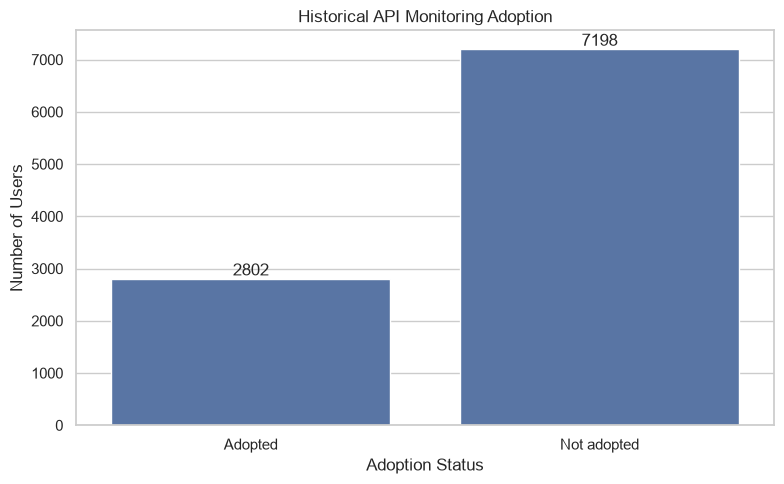

In [8]:
# Step 6: API Monitoring Adoption Chart

adopters = api_monitoring["user_id"].nunique()
non_adopters = users["user_id"].nunique() - adopters

adoption_counts = pd.DataFrame({
    "adoption_status": ["Adopted", "Not adopted"],
    "users": [adopters, non_adopters]
})

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=adoption_counts,
    x="adoption_status",
    y="users"
)

plt.title("Historical API Monitoring Adoption")
plt.xlabel("Adoption Status")
plt.ylabel("Number of Users")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.tight_layout()

plt.savefig(
    "../visualizations/api_monitoring_historical_adoption.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Explore feature usage distribution :

In [9]:
# Step 7: Feature Usage Distribution

feature_distribution = (
    feature_usage.groupby("feature_name")
    .agg(
        unique_users=("user_id", "nunique"),
        total_usage_records=("usage_id", "count"),
        average_usage=("usage_count", "mean")
    )
    .reset_index()
    .sort_values("unique_users", ascending=False)
)

display(feature_distribution)

,feature_name,unique_users,total_usage_records,average_usage
3,Analytics Dashboard,2945,2945,250.48
6,Webhooks,2913,2913,246.60
1,API Documentation,2873,2873,252.04
4,Rate Limiting,2869,2869,245.76
5,SDK Integration,2843,2843,253.82
2,API Monitoring,2802,2802,249.87
0,API Authentication,2796,2796,242.52


#### Visualize:

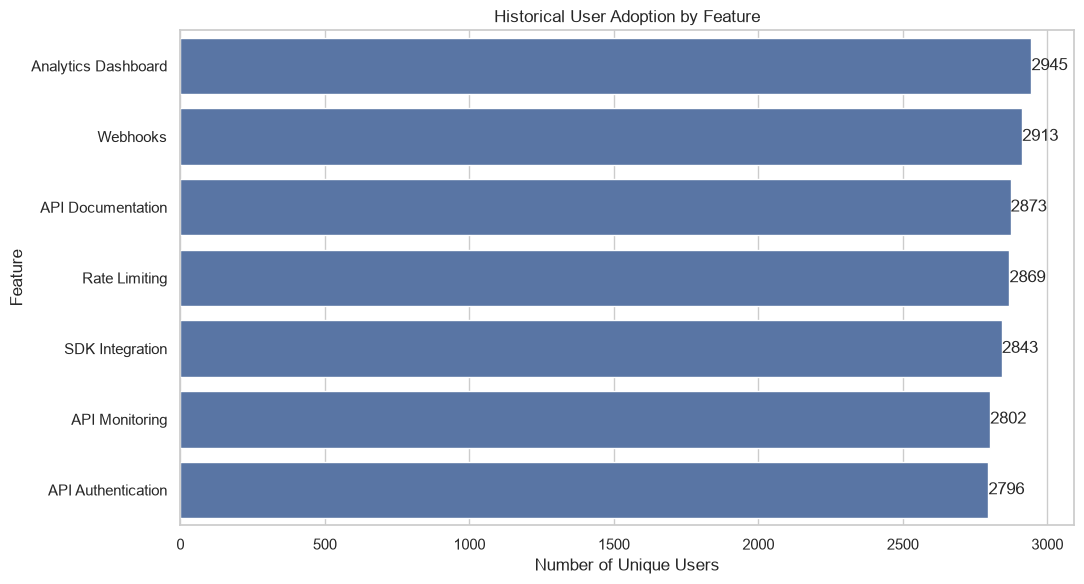

In [10]:
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=feature_distribution,
    x="unique_users",
    y="feature_name"
)

plt.title("Historical User Adoption by Feature")
plt.xlabel("Number of Unique Users")
plt.ylabel("Feature")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.tight_layout()

plt.savefig(
    "../visualizations/feature_usage_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Save initial EDA outputs :

In [11]:
# Step 8: Save EDA Tables

OUTPUT_DIR = Path("../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

dataset_summary.to_csv(
    OUTPUT_DIR / "ml_eda_dataset_summary.csv",
    index=False
)

adoption_summary.to_csv(
    OUTPUT_DIR / "api_monitoring_adoption_summary.csv",
    index=False
)

feature_distribution.to_csv(
    OUTPUT_DIR / "ml_eda_feature_distribution.csv",
    index=False
)

print("Initial EDA tables saved successfully.")

Initial EDA tables saved successfully.


### Analyze user engagement :

In [12]:
# Step 9: User Engagement Analysis

user_engagement = (
    product_events.groupby("user_id")
    .agg(
        total_events=("event_id", "count"),
        active_days=("event_timestamp", "nunique"),
        sessions=("session_id", "nunique")
    )
    .reset_index()
)

display(user_engagement.head())
print("Total users with product events:", user_engagement["user_id"].nunique())

,user_id,total_events,active_days,sessions
0,1,10,10,10
1,2,13,13,13
2,3,7,7,7
3,4,10,10,10
4,5,8,8,8


Total users with product events: 9999


#### inspect the engagement distribution

In [13]:
# Step 9.1: Engagement Statistics

display(
    user_engagement[
        ["total_events", "active_days", "sessions"]
    ].describe().T
)

,count,mean,std,min,25%,50%,75%,max
total_events,9999.00,8.00,2.83,1.00,6.00,8.00,10.00,19.00
active_days,9999.00,7.83,2.73,1.00,6.00,8.00,10.00,18.00
sessions,9999.00,8.00,2.83,1.00,6.00,8.00,10.00,19.00


#### Visualize the distribution of product events

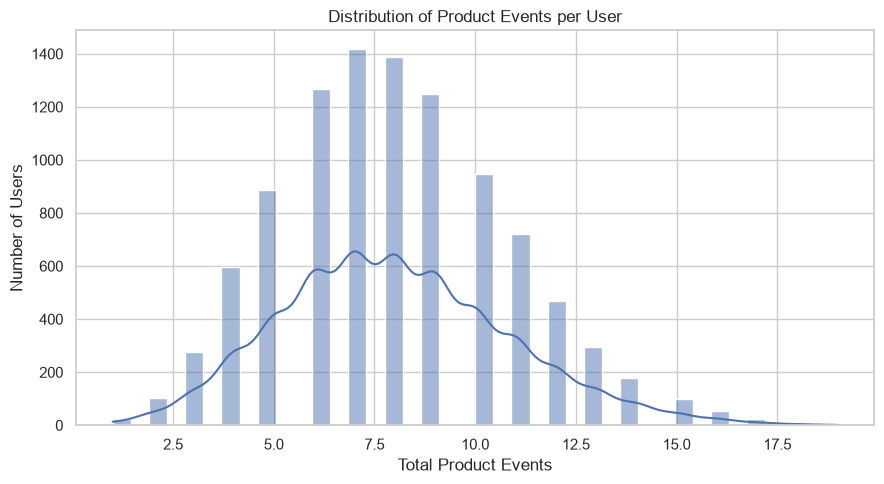

In [14]:
# Step 9.2: Product Events Distribution

plt.figure(figsize=(9, 5))

sns.histplot(
    data=user_engagement,
    x="total_events",
    bins=40,
    kde=True
)

plt.title("Distribution of Product Events per User")
plt.xlabel("Total Product Events")
plt.ylabel("Number of Users")

plt.tight_layout()

plt.savefig(
    "../visualizations/user_product_events_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Analyze API activity :

In [15]:
# Step 10: API Activity Analysis

user_api_activity = (
    api_usage.groupby("user_id")
    .agg(
        total_api_requests=("request_count", "sum"),
        total_api_success=("success_count", "sum"),
        total_api_errors=("error_count", "sum"),
        avg_response_time=("response_time_ms", "mean"),
        unique_endpoints=("endpoint", "nunique")
    )
    .reset_index()
)

user_api_activity["api_error_rate"] = np.where(
    user_api_activity["total_api_requests"] > 0,
    (
        user_api_activity["total_api_errors"]
        / user_api_activity["total_api_requests"]
    ) * 100,
    0
)

display(user_api_activity.head())

,user_id,total_api_requests,total_api_success,total_api_errors,avg_response_time,unique_endpoints,api_error_rate
0,1,4080,3860,220,551.32,4,5.39
1,2,4023,3795,228,439.28,4,5.67
2,3,995,955,40,578.74,4,4.02
3,4,3016,2875,141,585.15,5,4.68
4,5,2540,2402,138,592.84,3,5.43


#### Review the statistical distribution

In [16]:
# Step 10.1: API Activity Statistics

display(
    user_api_activity[
        [
            "total_api_requests",
            "total_api_success",
            "total_api_errors",
            "avg_response_time",
            "unique_endpoints",
            "api_error_rate"
        ]
    ].describe().T
)

,count,mean,std,min,25%,50%,75%,max
total_api_requests,9924.00,2542.39,1283.62,13.00,1605.75,2406.00,3310.25,8463.00
total_api_success,9924.00,2415.30,1219.55,12.00,1526.00,2285.00,3148.00,8049.00
total_api_errors,9924.00,127.09,65.06,0.00,80.00,120.00,166.00,427.00
avg_response_time,9924.00,510.68,143.50,24.50,419.78,510.79,602.34,996.82
unique_endpoints,9924.00,3.41,1.18,1.00,3.00,3.00,4.00,6.00
api_error_rate,9924.00,5.00,0.55,0.00,4.69,4.99,5.30,12.20


#### Visualize API requests

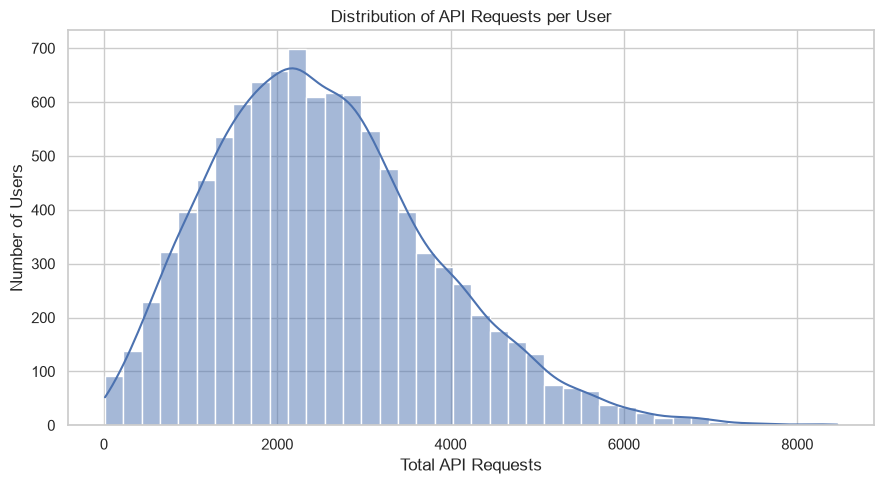

In [17]:
# Step 10.2: API Request Distribution

plt.figure(figsize=(9, 5))

sns.histplot(
    data=user_api_activity,
    x="total_api_requests",
    bins=40,
    kde=True
)

plt.title("Distribution of API Requests per User")
plt.xlabel("Total API Requests")
plt.ylabel("Number of Users")

plt.tight_layout()

plt.savefig(
    "../visualizations/user_api_requests_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Analyze subscription characteristics :

In [18]:
# Step 11: User Subscription Analysis

user_subscription = users.merge(
    organizations,
    on="organization_id",
    how="left",
    suffixes=("_user", "_organization")
)

user_subscription = user_subscription.merge(
    subscriptions[
        [
            "organization_id",
            "plan_type",
            "subscription_status",
            "monthly_price",
            "start_date",
            "end_date"
        ]
    ],
    on="organization_id",
    how="left"
)

display(user_subscription.head())

,user_id,organization_id,signup_date,country_user,user_role,acquisition_channel,is_verified,organization_name,industry,company_size,created_date,country_organization,plan_type,subscription_status,monthly_price,start_date,end_date
0,1398,302,2024-01-10,Germany,Admin,Organic,1,Organization_302,Technology,Medium,2024-01-07,India,Pro,Cancelled,49.00,2024-02-14,2024-03-03
1,9381,194,2024-01-18,Singapore,Admin,Paid Ads,1,Organization_194,Education,Medium,2024-01-01,Japan,Pro,Active,49.00,2024-01-16,NaT
2,2037,424,2024-01-23,Singapore,Admin,Social Media,0,Organization_424,Retail,Medium,2024-01-20,India,Pro,Active,49.00,2024-02-18,NaT
3,9249,718,2024-01-25,Japan,Admin,Organic,0,Organization_718,Finance,Small,2024-01-17,Germany,Enterprise,Active,199.00,2024-07-10,NaT
4,1565,469,2024-02-02,Japan,Admin,Referral,1,Organization_469,Retail,Large,2024-01-22,USA,Free,Active,0.00,2024-05-24,NaT


#### Check the distribution of subscription plans

In [19]:
# Step 11.1: Subscription Plan Distribution

plan_distribution = (
    user_subscription.groupby("plan_type", dropna=False)
    .agg(
        users=("user_id", "nunique"),
        average_monthly_price=("monthly_price", "mean")
    )
    .reset_index()
)

display(plan_distribution)

,plan_type,users,average_monthly_price
0,Enterprise,2048,199.00
1,Free,4130,0.00
2,Pro,3822,49.00


#### Visualize user counts by plan

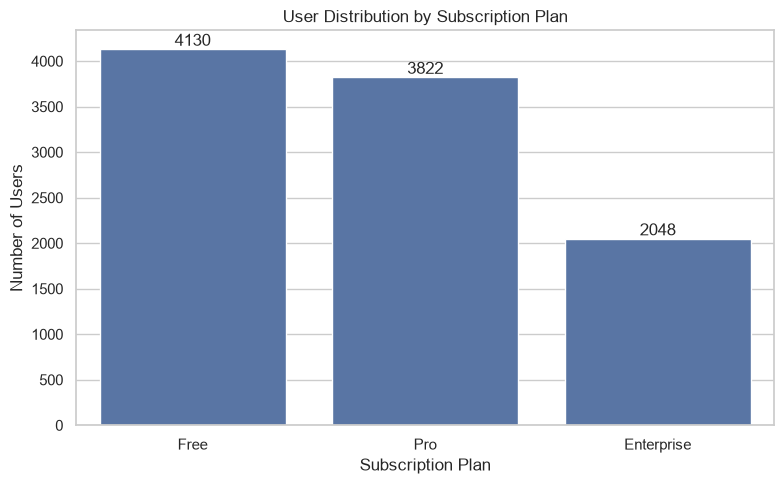

In [20]:
# Step 11.2: Subscription Plan Chart

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=user_subscription,
    x="plan_type",
    order=user_subscription["plan_type"].value_counts().index
)

plt.title("User Distribution by Subscription Plan")
plt.xlabel("Subscription Plan")
plt.ylabel("Number of Users")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.tight_layout()

plt.savefig(
    "../visualizations/user_subscription_plan_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Build a historical adoption analysis table :

In [21]:
# Step 12: Historical Adoption Label

api_monitoring_users = set(
    feature_usage.loc[
        feature_usage["feature_name"] == "API Monitoring",
        "user_id"
    ].unique()
)

historical_adoption = users[["user_id", "organization_id"]].copy()

historical_adoption["historical_api_monitoring_adopted"] = (
    historical_adoption["user_id"].isin(api_monitoring_users).astype(int)
)

print(
    historical_adoption[
        "historical_api_monitoring_adopted"
    ].value_counts()
)

display(historical_adoption.head())

historical_api_monitoring_adopted
0    7198
1    2802
Name: count, dtype: int64


,user_id,organization_id,historical_api_monitoring_adopted
0,1398,302,1
1,9381,194,0
2,2037,424,0
3,9249,718,0
4,1565,469,0


### Explore engagement and historical adoption :

In [22]:
# Step 13: Engagement vs Historical Adoption

engagement_adoption = user_engagement.merge(
    historical_adoption[
        ["user_id", "historical_api_monitoring_adopted"]
    ],
    on="user_id",
    how="left"
)

engagement_comparison = (
    engagement_adoption.groupby(
        "historical_api_monitoring_adopted"
    )
    .agg(
        users=("user_id", "nunique"),
        avg_events=("total_events", "mean"),
        avg_active_days=("active_days", "mean"),
        avg_sessions=("sessions", "mean")
    )
    .reset_index()
)

display(engagement_comparison)

,historical_api_monitoring_adopted,users,avg_events,avg_active_days,avg_sessions
0,0,7198,8.00,7.82,8.00
1,1,2801,8.01,7.83,8.01


### Explore API activity and historical adoption :

In [23]:
# Step 14: API Activity vs Historical Adoption

api_adoption_analysis = user_api_activity.merge(
    historical_adoption[
        ["user_id", "historical_api_monitoring_adopted"]
    ],
    on="user_id",
    how="left"
)

api_adoption_comparison = (
    api_adoption_analysis.groupby(
        "historical_api_monitoring_adopted"
    )
    .agg(
        users=("user_id", "nunique"),
        avg_api_requests=("total_api_requests", "mean"),
        avg_api_errors=("total_api_errors", "mean"),
        avg_response_time=("avg_response_time", "mean"),
        avg_error_rate=("api_error_rate", "mean"),
        avg_unique_endpoints=("unique_endpoints", "mean")
    )
    .reset_index()
)

display(api_adoption_comparison)

,historical_api_monitoring_adopted,users,avg_api_requests,avg_api_errors,avg_response_time,avg_error_rate,avg_unique_endpoints
0,0,7141,2554.14,127.70,511.58,5.00,3.41
1,1,2783,2512.24,125.52,508.37,4.99,3.40


### Save the analysis outputs :

In [24]:
# Step 15: Save ML EDA Results

OUTPUT_DIR = Path("../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

user_engagement.to_csv(
    OUTPUT_DIR / "ml_eda_user_engagement.csv",
    index=False
)

user_api_activity.to_csv(
    OUTPUT_DIR / "ml_eda_user_api_activity.csv",
    index=False
)

plan_distribution.to_csv(
    OUTPUT_DIR / "ml_eda_subscription_distribution.csv",
    index=False
)

engagement_comparison.to_csv(
    OUTPUT_DIR / "ml_eda_engagement_adoption_comparison.csv",
    index=False
)

api_adoption_comparison.to_csv(
    OUTPUT_DIR / "ml_eda_api_adoption_comparison.csv",
    index=False
)

print("ML EDA analysis outputs saved successfully.")

ML EDA analysis outputs saved successfully.
